# EJEMPLO 1
## Entrenamiento desde cero

En este cuaderno se mostrará como crear una red profunda desde cero creando cada una de las capas y realizando el entrenamiento y validación para clasificar los números manuscritos.


**Carga la biblioteca TensorFlow**

In [1]:
import tensorflow as tf
print("Versión TF", tf.__version__)

Versión TF 2.21.0


**Carga el dataset de caracteres manuscritos MNIST**

Puedes usar como prompt para Gemini:

> Incluye el código para carga el dataset MNIST, tanto el conjunto de entrenamiento como el conjunto de prueba. Muéstrame la imagen de una de las imágenes de entrenamiento, por ejemplo, la de índice 10



11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Conjunto de entrenamiento: (60000, 28, 28) imágenes de 28x28 píxeles
Conjunto de prueba: (10000, 28, 28) imágenes de 28x28 píxeles


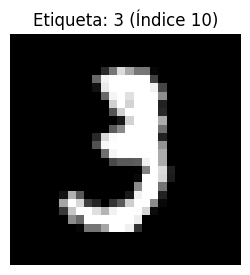

In [2]:
import matplotlib.pyplot as plt

# Cargar el dataset MNIST
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print(f"Conjunto de entrenamiento: {x_train.shape} imágenes de {x_train.shape[1]}x{x_train.shape[2]} píxeles")
print(f"Conjunto de prueba: {x_test.shape} imágenes de {x_test.shape[1]}x{x_test.shape[2]} píxeles")

# Mostrar la imagen de entrenamiento con índice 10
indice = 10
plt.figure(figsize=(3, 3))
plt.imshow(x_train[indice], cmap='gray')
plt.title(f"Etiqueta: {y_train[indice]} (Índice {indice})")
plt.axis('off')
plt.show()

**Crea un modelo desde cero**

Puedes usar como prompt:


> Créame un modelo profundo que tenga dos capas convolucionales seguidas de capas de maxpool y una capa densa para clasificar las imágenes de MINST. Usa la API funcional. Recuerda realizar una normalización de los dataset de entrenamiento y prueba.

La IA te puede generar un código diferente, a veces usando una directiva llamada Sequential, la cual es útil cuando el modelo es un conjunto secuencial de capas. Pero si el modelo usa capas como las residuales es necesario emplear la API funcional.


In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Normalizar y preparar las dimensiones de los conjuntos de datos
x_train_normalized = x_train.astype("float32") / 255.0
x_test_normalized = x_test.astype("float32") / 255.0

x_train_normalized = x_train_normalized[..., tf.newaxis]
x_test_normalized = x_test_normalized[..., tf.newaxis]

# 2. Definición del modelo usando la API Funcional
def create_model():
    # Definir la capa de entrada
    inputs = layers.Input(shape=(28, 28, 1))

    # Primera capa convolucional + MaxPool
    x = layers.Conv2D(32, (3, 3), activation='relu')(inputs)
    x = layers.MaxPooling2D((2, 2))(x)

    # Segunda capa convolucional + MaxPool
    x = layers.Conv2D(64, (3, 3), activation='relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Aplanado y capas densas para clasificación
    x = layers.Flatten()(x)
    x = layers.Dense(64, activation='relu')(x)
    outputs = layers.Dense(10, activation='softmax')(x)

    # Crear el objeto Model asociando las entradas y las salidas
    model = models.Model(inputs=inputs, outputs=outputs)

    return model

# 3. Instanciar el modelo
model = create_model()

# Mostrar el resumen de las capas creadas
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

**Crea el conjunto de validación**

MINST ya está particionado en conjunto de entrenamiento y prueba. Estos conjuntos son empleados durante el proceso de entrenamiento. Pero para generar las métricas finales se recomienda contar con un conjunto de prueba separado. Para crearlo, es posible partir el conjunto de prueba en 2, donde el 50% sea para el proceso de entrenamiento (_validation set_)y el otro 50% para cálculo de métricas (_test set_).

Usa el prompt:


> Parte el conjunto de prueba en 2, para que el 50% de las imágenes sea un conjunto de prueba y el otro 50% sea el conjunto de validación.



In [4]:
# Partir el conjunto de prueba en 50% prueba y 50% validación
limite = len(x_test_normalized) // 2

# Conjunto de validación (primeros 5,000 elementos)
x_val = x_test_normalized[:limite]
y_val = y_test[:limite]

# Conjunto de prueba (restantes 5,000 elementos)
x_test_split = x_test_normalized[limite:]
y_test_split = y_test[limite:]

print(f"Dimensiones de Validación (x, y): {x_val.shape}, {y_val.shape}")
print(f"Dimensiones de Prueba (x, y): {x_test_split.shape}, {y_test_split.shape}")

Dimensiones de Validación (x, y): (5000, 28, 28, 1), (5000,)
Dimensiones de Prueba (x, y): (5000, 28, 28, 1), (5000,)


**Entrenamiento**

Ahora vamos a entrenar el modelo, pero queremos que conforme se esté entrenando el modelo se verifique la función de loss y accuracy para evitar overfitting.

Usa el prompt:

> Compila el modelo usando el optimizar adam, realiza el entrenamiento para 20 épocas con el conjunto de entrenamiento y prueba, y añade paradas tempranas de EarlyStopping y Checkpoints. Además, necesito que al final del entrenamiento genere las gráficas de accuracy y loss para los conjuntos de entrenamiento y validación.

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9920 - loss: 0.0249
Epoch 1: val_loss improved from None to 0.06502, saving model to mejor_modelo.keras

Epoch 1: finished saving model to mejor_modelo.keras
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.9921 - loss: 0.0249 - val_accuracy: 0.9802 - val_loss: 0.0650
Epoch 2/10
936/938 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9944 - loss: 0.0174
Epoch 2: val_loss improved from 0.06502 to 0.04704, saving model to mejor_modelo.keras

Epoch 2: finished saving model to mejor_modelo.keras
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9943 - loss: 0.0176 - val_accuracy: 0.9842 - val_loss: 0.0470
Epoch 3/10
933/938 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9960 - loss: 0.0129
Epoch 3: val_loss improved from 0.04704 to 0.04484, saving model to mejor_modelo.keras

Epoch 3: finished saving model to mejor_modelo.keras
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9956 - loss: 0.0138 - val_accura

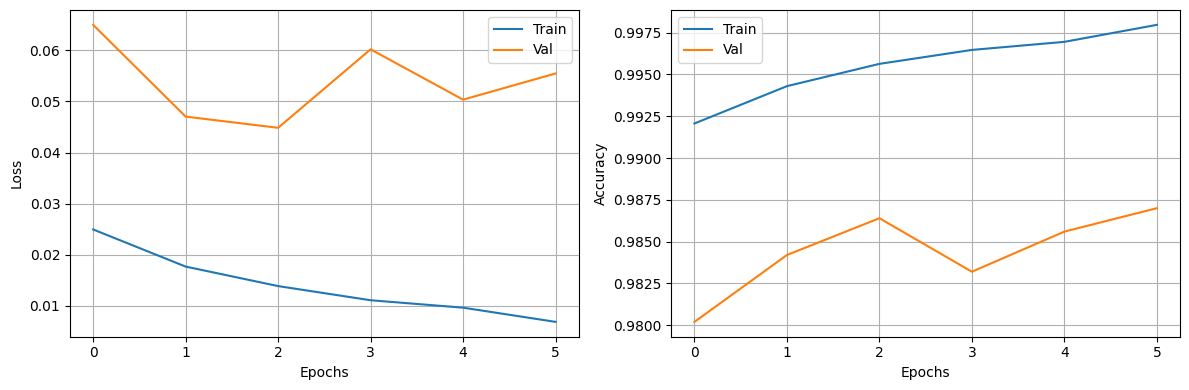

In [7]:
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# 1. Compilar el modelo con el optimizador Adam y la pérdida correspondiente
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 2. Configurar los Callbacks (EarlyStopping y ModelCheckpoint)
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath='mejor_modelo.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

# 3. Entrenar el modelo por 20 épocas usando el conjunto de entrenamiento y validación
history = model.fit(
    x_train_normalized, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=callbacks
)

# 4. Generar las gráficas de Accuracy y Loss para ambos conjuntos
plt.figure(figsize=(12, 4))

# Gráfica de Pérdida (Loss)
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Gráfica de Precisión (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Calcula métricas de evaluación del modelo**

Usando el modelo de validación, realiza un cálculo de las siguientes métricas:

* Accuracy (Exactitud): Porcentaje de todas las predicciones que fueron correctas (sobre el total de las muestras).

* Precision: Porcentaje de predicciones positivas que fueron realmente positivas (considerando el efecto de los falsos positivos): $\frac{TP}{TP+FP}$

* Recall: Porcentaje de predicciones positivas que fueron realmente positivas (considerando el efecto de los falsos negativos): $\frac{TP}{TP+FN}$

* f1-score: Ponderación de precisión y recall. Útil para dataset desbalanceados

* Matriz de confusión para analizar de que manera se distribuye la clasificación para todas las clases.

Usa el prompt:

> Calcula las métricas de accuray, precision, recall y f1-score para clase a identificar del conjunto de prueba. Calcula también la matriz de confusión.

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
=== REPORTE DE CLASIFICACIÓN (Conjunto de Validación) ===
              precision    recall  f1-score   support

           0     0.9981    0.9942    0.9961       520
           1     0.9930    1.0000    0.9965       564
           2     0.9881    0.9960    0.9921       502
           3     0.9961    0.9941    0.9951       510
           4     1.0000    0.9917    0.9958       482
           5     1.0000    0.9908    0.9954       436
           6     0.9980    0.9960    0.9970       496
           7     0.9923    0.9942    0.9932       516
           8     0.9959    0.9959    0.9959       485
           9     0.9878    0.9939    0.9908       489

    accuracy                         0.9948      5000
   macro avg     0.9949    0.9947    0.9948      5000
weighted avg     0.9948    0.9948    0.9948      5000



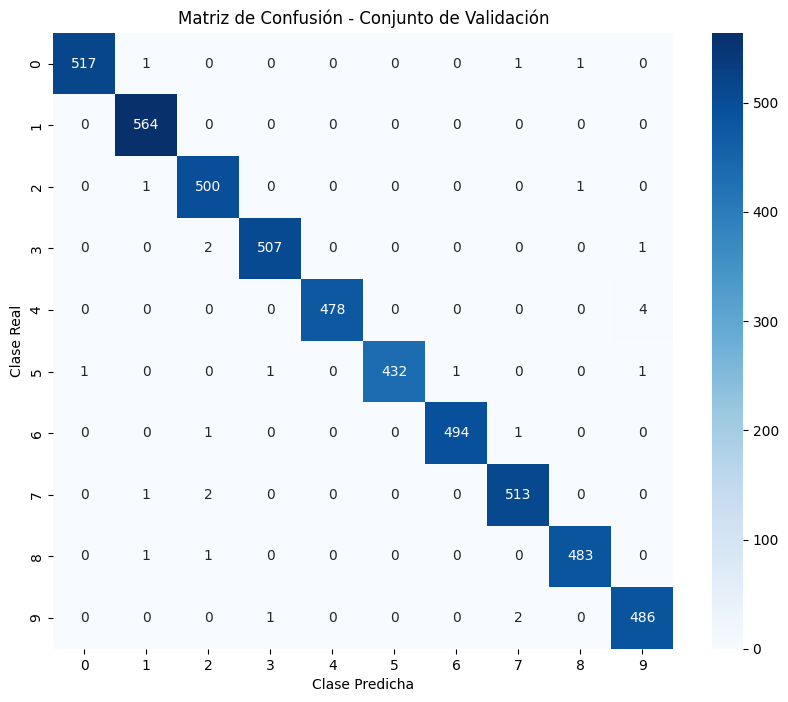

In [8]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

# 1. Obtener las predicciones del modelo para el conjunto de validación
predicciones_prob = model.predict(x_test_split)
predicciones = np.argmax(predicciones_prob, axis=1)

# 2. Calcular y mostrar el reporte de clasificación
print("=== REPORTE DE CLASIFICACIÓN (Conjunto de Validación) ===")
print(classification_report(y_test_split, predicciones, digits=4))

# 3. Calcular la matriz de confusión
matriz_confusion = confusion_matrix(y_test_split, predicciones)

# 4. Graficar la matriz de confusión
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues',
            xticklabels=list(range(10)), yticklabels=list(range(10)))
plt.title('Matriz de Confusión - Conjunto de Validación')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.show()

**Guarda el modelo**

In [ ]:
model.save("clasificador_digitos.keras")